# Análisis exploratorio

*Mantenimiento Predictivo para Aerogeneradores Offshore con Restricciones Ambientales. Trabajo de Fin de Máster. Primero de los ocho notebooks*

CARE To Compare es un *benchmark* público de datos SCADA con eventos de fallo etiquetados. Este trabajo usa sus dos parques marinos, B y C, aquí se analizan: volumen, catálogo de canales, estado operativo, continuidad temporal, calidad del registro y anatomía de los eventos de anomalía.

**La conclusión a la que se llega es que los dos parques no admiten el mismo tratamiento, y que esa divergencia no es un accidente de configuración sino una propiedad del dato.** Un parque pequeño, ruidoso y de eventos largos frente a otro grande, limpio y con un amplio abanico de casos.

## 1. Preparación del entorno

In [1]:
import os
import sys
import warnings
from pathlib import Path
from datetime import datetime, timedelta
from typing import Dict, List, Tuple, Optional

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import MaxNLocator
import seaborn as sns

from scipy import stats
from scipy.stats import pearsonr, spearmanr

from tqdm.notebook import tqdm

warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.width', None)
pd.set_option('display.float_format', '{:.4f}'.format)

print(f"Python version: {sys.version}")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Python version: 3.12.12 (main, Dec 17 2025, 21:10:14) [MSC v.1944 64 bit (AMD64)]
Pandas version: 3.0.0
NumPy version: 2.4.2


### 1.1 Estilo de las figuras

In [2]:
# Estilo de visualizacion
plt.style.use('seaborn-v0_8-whitegrid')

COLORS = {
    'blue': '#648FFF',
    'purple': '#785EF0',
    'magenta': '#DC267F',
    'orange': '#FE6100',
    'yellow': '#FFB000',
    'gray': '#808080',
    'dark_gray': '#404040',
    'light_gray': '#D0D0D0'
}

# Colores por granja
FARM_COLORS = {
    'B': COLORS['blue'],
    'C': COLORS['orange']
}

# Colores de estado
STATUS_COLORS = {
    0: '#2E7D32',  # Normal Operation - Green
    1: '#FFA726',  # Derated - Orange
    2: '#42A5F5',  # Idling - Blue
    3: '#AB47BC',  # Service - Purple
    4: '#EF5350',  # Downtime - Red
    5: '#78909C'   # Other - Gray
}

# Colores de etiqueta
LABEL_COLORS = {
    'anomaly': COLORS['magenta'],
    'normal': COLORS['blue']
}

# Configuración de figuras
FIGURE_DPI = 300
FIGURE_FORMAT = 'png'

# Configuración por defecto de matplotlib
plt.rcParams.update({
    'figure.figsize': (12, 6),
    'figure.dpi': 100,
    'savefig.dpi': FIGURE_DPI,
    'savefig.bbox': 'tight',
    'font.size': 11,
    'axes.titlesize': 13,
    'axes.labelsize': 11,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'axes.spines.top': False,
    'axes.spines.right': False
})

### 1.2 Rutas y constantes

La raíz del repositorio se resuelve con `Path.cwd().parent`, de modo que el notebook **solo funciona lanzado desde `notebooks/`**.

In [3]:
# Rutas del proyecto
PROJECT_ROOT = Path.cwd().parent
DATA_RAW = PROJECT_ROOT / 'data' / 'raw' / 'CARE_To_Compare'
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'
RESULTS_FIGURES = PROJECT_ROOT / 'results' / 'figures'
RESULTS_TABLES = PROJECT_ROOT / 'results' / 'tables'

# Crear directorios de salida si no existen
RESULTS_FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS_TABLES.mkdir(parents=True, exist_ok=True)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

# Rutas de granjas (solo B y C - offshore)
FARM_PATHS = {
    'B': DATA_RAW / 'Wind Farm B',
    'C': DATA_RAW / 'Wind Farm C'
}

# Definición de tipos de estado según documentación CARE
STATUS_TYPES = {
    0: 'Normal Operation',
    1: 'Derated Operation',
    2: 'Idling',
    3: 'Service',
    4: 'Downtime',
    5: 'Other'
}

# IDs de estado de operación normal (usados para entrenamiento NBM)
NORMAL_STATUS_IDS = [0, 2]

# Frecuencia de datos
DATA_FREQUENCY_MINUTES = 10

# Verificar que existen las rutas
print("Verifying data paths...")
for farm, path in FARM_PATHS.items():
    if path.exists():
        print(f"  Farm {farm}: {path} [OK]")
    else:
        print(f"  Farm {farm}: {path} [NOT FOUND]")

print(f"\nOutput directories:")
print(f"  Figures: {RESULTS_FIGURES}")
print(f"  Tables: {RESULTS_TABLES}")

Verifying data paths...
  Farm B: .\data\raw\CARE_To_Compare\Wind Farm B [OK]
  Farm C: .\data\raw\CARE_To_Compare\Wind Farm C [OK]

Output directories:
  Figures: .\results\figures
  Tables: .\results\tables


### 1.3 Funciones auxiliares

Utilidades de carga, procesamiento y visualización que se reutilizan a lo largo del análisis.

In [4]:
def load_event_info(farm: str) -> pd.DataFrame:
    path = FARM_PATHS[farm] / 'event_info.csv'
    df = pd.read_csv(path, sep=';')
    df['farm'] = farm
    
    # Parsear columnas datetime
    df['event_start'] = pd.to_datetime(df['event_start'])
    df['event_end'] = pd.to_datetime(df['event_end'])
    
    # Calcular duración del evento
    df['duration_days'] = (df['event_end'] - df['event_start']).dt.total_seconds() / 86400
    
    return df


def load_feature_description(farm: str) -> pd.DataFrame:
    path = FARM_PATHS[farm] / 'feature_description.csv'
    df = pd.read_csv(path, sep=';')
    df['farm'] = farm
    return df


def load_dataset(farm: str, event_id: int, parse_dates: bool = True) -> pd.DataFrame:
    path = FARM_PATHS[farm] / 'datasets' / f'{event_id}.csv'
    df = pd.read_csv(path, sep=';')
    
    if parse_dates:
        df['time_stamp'] = pd.to_datetime(df['time_stamp'])
    
    df['farm'] = farm
    df['event_id'] = event_id
    
    return df


def get_dataset_files(farm: str) -> List[int]:
    datasets_path = FARM_PATHS[farm] / 'datasets'
    event_ids = [int(f.stem) for f in datasets_path.glob('*.csv')]
    return sorted(event_ids)


def save_figure(fig: plt.Figure, filename: str, tight: bool = True) -> None:
    path = RESULTS_FIGURES / f"{filename}.{FIGURE_FORMAT}"
    bbox = 'tight' if tight else None
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches=bbox, facecolor='white')
    print(f"Saved: {path}")


def save_table(df: pd.DataFrame, filename: str, index: bool = False) -> None:
    path = RESULTS_TABLES / f"{filename}.csv"
    df.to_csv(path, index=index)
    print(f"Saved: {path}")


def calculate_memory_usage(df: pd.DataFrame) -> str:
    bytes_used = df.memory_usage(deep=True).sum()
    if bytes_used < 1024:
        return f"{bytes_used} B"
    elif bytes_used < 1024**2:
        return f"{bytes_used/1024:.2f} KB"
    elif bytes_used < 1024**3:
        return f"{bytes_used/1024**2:.2f} MB"
    else:
        return f"{bytes_used/1024**3:.2f} GB"

## 2. Carga de datos e inspección inicial

Carga los 15 *sub-datasets* del parque B y los 58 del parque C, construye la ficha de cada parque y da una primera visión de la estructura. Cada *sub-dataset* contiene en torno a un año de historia de una única turbina.

### 2.1 Información de eventos

Metadatos de los eventos de los dos parques: la etiqueta (anomalía o normal) y las marcas temporales de inicio y fin.

In [5]:
# Cargar informacion de eventos de ambas granjas
event_info_b = load_event_info('B')
event_info_c = load_event_info('C')

# Combinar en un unico DataFrame
event_info = pd.concat([event_info_b, event_info_c], ignore_index=True)

print(f"Total events loaded: {len(event_info)}")
print(f"  Farm B: {len(event_info_b)} events")
print(f"  Farm C: {len(event_info_c)} events")
print(f"\nLabel distribution:")
print(event_info.groupby(['farm', 'event_label']).size().unstack(fill_value=0))

Total events loaded: 73
  Farm B: 15 events
  Farm C: 58 events

Label distribution:
event_label  anomaly  normal
farm                        
B                  6       9
C                 27      31


In [6]:
# Mostrar muestra de informacion de eventos
print("Sample event information (first 10 rows):")
event_info[['event_id', 'farm', 'event_label', 'event_start', 'event_end', 'duration_days', 'event_description']].head(10)

Sample event information (first 10 rows):


,event_id,farm,event_label,event_start,event_end,duration_days,event_description
0,34,B,anomaly,2023-08-24 00:00:00,2023-09-15 00:00:00,22.0000,high temperature in transformer cell
1,7,B,anomaly,2023-07-01 00:00:00,2023-08-01 00:00:00,31.0000,high temperature in transformer cell
2,53,B,anomaly,2023-12-26 16:40:00,2024-02-06 16:30:00,41.9931,Rotor Bearing 2 - Damage
3,27,B,anomaly,2023-09-01 00:00:00,2023-11-01 00:00:00,61.0000,Turbine is stopped due to a main bearing damage
4,19,B,anomaly,2023-02-03 00:00:00,2023-02-23 00:00:00,20.0000,high temperature in transformer cell
5,77,B,anomaly,2023-06-01 00:00:00,2023-07-31 00:00:00,60.0000,Turbine is in standstill since 01.08 due to ro...
6,83,B,normal,2023-07-01 00:00:00,2023-09-30 00:00:00,91.0000,NaN
7,52,B,normal,2023-07-14 00:00:00,2023-07-28 00:00:00,14.0000,NaN
8,21,B,normal,2023-09-22 20:10:00,2023-10-01 20:10:00,9.0000,NaN
9,2,B,normal,2023-08-09 19:20:00,2023-08-23 04:20:00,13.3750,NaN


### 2.2 Descripciones de los canales

Metadatos de los sensores, para saber qué mide cada canal.

> «Canal» designa el sensor físico y «variable» cada una de sus cuatro agregaciones diezminutales (la media, la desviación típica, el mínimo y el máximo), que son las columnas que los modelos reciben como entrada.

In [7]:
# Cargar descripciones de features
features_b = load_feature_description('B')
features_c = load_feature_description('C')

print(f"Feature descriptions loaded:")
print(f"  Farm B: {len(features_b)} sensors")
print(f"  Farm C: {len(features_c)} sensors")

# Calcular total de features (sensores estadisticos)
def count_total_features(features_df):
    total = 0
    for _, row in features_df.iterrows():
        stats = row['statistics_type'].split(',')
        total += len(stats)
    return total

print(f"\nTotal feature columns (sensor * statistics):")
print(f"  Farm B: {count_total_features(features_b)} features")
print(f"  Farm C: {count_total_features(features_c)} features")

Feature descriptions loaded:
  Farm B: 63 sensors
  Farm C: 238 sensors

Total feature columns (sensor * statistics):
  Farm B: 252 features
  Farm C: 952 features


In [8]:
# Mostrar muestra de descripciones de features de la Granja B
print("Farm B - Sample feature descriptions:")
features_b[['sensor_name', 'description', 'unit', 'statistics_type']].head(15)

Farm B - Sample feature descriptions:


,sensor_name,description,unit,statistics_type
0,sensor_0,Total negative reactive power,kvarh,"maximum,minimum,average,std_dev"
1,sensor_1,Total negative active power,kWh,"maximum,std_dev,average,minimum"
2,sensor_2,Total positive reactive power,kvarh,"average,minimum,maximum,std_dev"
3,sensor_3,Total positive active power,kWh,"maximum,std_dev,minimum,average"
4,sensor_4,Absolute wind direction,�,"average,maximum,minimum,std_dev"
5,sensor_5,Torque delta calculated,kNm,"average,maximum,std_dev,minimum"
6,sensor_6,Wind speed anemometer 2 calculated,m/s,"average,minimum,std_dev,maximum"
7,sensor_7,Cable load,%,"std_dev,maximum,minimum,average"
8,sensor_8,Outside temperature,�C,"maximum,average,minimum,std_dev"
9,sensor_9,Estimated tower natural frequency,mHz,"average,minimum,maximum,std_dev"


### 2.3 Ficha de los dos parques

Recorre todos los ficheros para contar filas, rangos de fechas, turbinas y distribución de estados.

In [9]:
def create_dataset_summary() -> pd.DataFrame:
    summaries = []
    
    for farm in ['B', 'C']:
        event_ids = get_dataset_files(farm)
        farm_event_info = event_info[event_info['farm'] == farm]
        
        for event_id in tqdm(event_ids, desc=f"Processing Farm {farm}"):
            try:
                df = load_dataset(farm, event_id)
                
                # Obtener etiqueta del evento
                event_row = farm_event_info[farm_event_info['event_id'] == event_id]
                label = event_row['event_label'].values[0] if len(event_row) > 0 else 'unknown'
                description = event_row['event_description'].values[0] if len(event_row) > 0 else ''
                
                summary = {
                    'farm': farm,
                    'event_id': event_id,
                    'event_label': label,
                    'n_rows': len(df),
                    'n_columns': len(df.columns),
                    'n_turbines': df['asset_id'].nunique(),
                    'turbine_ids': sorted(df['asset_id'].unique().tolist()),
                    'start_date': df['time_stamp'].min(),
                    'end_date': df['time_stamp'].max(),
                    'train_rows': (df['train_test'] == 'train').sum(),
                    'test_rows': (df['train_test'] == 'test').sum(),
                    'memory_mb': df.memory_usage(deep=True).sum() / 1024**2,
                    'event_description': description
                }
                
                # Distribucion de estados
                status_counts = df['status_type_id'].value_counts().to_dict()
                for status_id in range(6):
                    summary[f'status_{status_id}_count'] = status_counts.get(status_id, 0)
                
                summaries.append(summary)
                
            except Exception as e:
                print(f"Error processing Farm {farm}, Event {event_id}: {e}")
    
    return pd.DataFrame(summaries)

# Crear resumen
print("Creating dataset summary...")
dataset_summary = create_dataset_summary()
print(f"\nSummary complete: {len(dataset_summary)} datasets processed")

Creating dataset summary...


Processing Farm B:   0%|          | 0/15 [00:00<?, ?it/s]

Processing Farm C:   0%|          | 0/58 [00:00<?, ?it/s]


Summary complete: 73 datasets processed


In [10]:
print("DATASET SUMMARY - OFFSHORE FARMS B AND C")

for farm in ['B', 'C']:
    farm_data = dataset_summary[dataset_summary['farm'] == farm]
    print(f"\n Wind Farm {farm} ")
    print(f"Number of datasets: {len(farm_data)}")
    print(f"  Anomaly events: {(farm_data['event_label'] == 'anomaly').sum()}")
    print(f"  Normal events: {(farm_data['event_label'] == 'normal').sum()}")
    print(f"Total data points: {farm_data['n_rows'].sum():,}")
    print(f"Number of features: {farm_data['n_columns'].iloc[0] - 5}")  # Subtract metadata columns
    print(f"Unique turbines: {len(set([t for tlist in farm_data['turbine_ids'] for t in tlist]))}")
    print(f"Date range: {farm_data['start_date'].min()} to {farm_data['end_date'].max()}")
    print(f"Total memory: {farm_data['memory_mb'].sum():.2f} MB")

print("\nCOMBINED TOTALS")
print(f"Total datasets: {len(dataset_summary)}")
print(f"Total anomaly events: {(dataset_summary['event_label'] == 'anomaly').sum()}")
print(f"Total normal events: {(dataset_summary['event_label'] == 'normal').sum()}")
print(f"Total data points: {dataset_summary['n_rows'].sum():,}")

DATASET SUMMARY - OFFSHORE FARMS B AND C

 Wind Farm B 
Number of datasets: 15
  Anomaly events: 6
  Normal events: 9
Total data points: 859,065
Number of features: 254
Unique turbines: 9
Date range: 2022-01-01 23:00:00 to 2024-02-06 16:30:00
Total memory: 1769.97 MB

 Wind Farm C 
Number of datasets: 58
  Anomaly events: 27
  Normal events: 31
Total data points: 3,187,136
Number of features: 954
Unique turbines: 22
Date range: 2022-01-06 00:00:00 to 2024-01-08 15:40:00
Total memory: 23587.20 MB
COMBINED TOTALS
Total datasets: 73
Total anomaly events: 33
Total normal events: 40
Total data points: 4,046,201


In [11]:
# Guardar resumen del dataset
save_table(dataset_summary, 'data_summary')

# Mostrar tabla resumen
dataset_summary[['farm', 'event_id', 'event_label', 'n_rows', 'n_columns', 'n_turbines', 'start_date', 'end_date']].head(20)

Saved: .\results\tables\data_summary.csv


,farm,event_id,event_label,n_rows,n_columns,n_turbines,start_date,end_date
0,B,2,normal,54774,259,1,2022-08-08 19:20:00,2023-08-24 04:20:00
1,B,7,anomaly,57888,259,1,2022-06-30 00:00:00,2023-08-06 00:00:00
2,B,19,anomaly,56274,259,1,2022-02-02 00:00:00,2023-02-28 00:00:00
3,B,21,normal,53514,259,1,2022-09-22 20:10:00,2023-10-01 20:10:00
4,B,23,normal,54542,259,1,2022-09-17 17:30:00,2023-10-01 11:50:00
5,B,27,anomaly,62268,259,1,2022-08-30 00:00:00,2023-11-07 00:00:00
6,B,34,anomaly,56564,259,1,2022-08-24 00:00:00,2023-09-21 00:00:00
7,B,52,normal,55268,259,1,2022-07-13 00:00:00,2023-08-01 00:00:00
8,B,53,anomaly,58607,259,1,2022-12-26 16:40:00,2024-02-06 16:30:00
9,B,74,normal,55602,259,1,2022-01-01 23:00:00,2023-01-23 07:00:00


### 2.4 Inspección de un *sub-dataset* de muestra

Examina la estructura de un *sub-dataset* de cada parque para entender el formato del registro.

In [12]:
# Cargar datasets de muestra
sample_event_b = dataset_summary[dataset_summary['farm'] == 'B']['event_id'].iloc[0]
sample_event_c = dataset_summary[dataset_summary['farm'] == 'C']['event_id'].iloc[0]

sample_df_b = load_dataset('B', sample_event_b)
sample_df_c = load_dataset('C', sample_event_c)

print(f"Sample from Farm B (Event {sample_event_b}):")
print(f"Shape: {sample_df_b.shape}")
print(f"Memory: {calculate_memory_usage(sample_df_b)}")
print(f"\nData types:")
print(sample_df_b.dtypes.value_counts())

Sample from Farm B (Event 2):
Shape: (54774, 259)
Memory: 112.84 MB

Data types:
float64           252
int64               4
str                 2
datetime64[us]      1
Name: count, dtype: int64


In [13]:
print(f"\nSample from Farm C (Event {sample_event_c}):")
print(f"Shape: {sample_df_c.shape}")
print(f"Memory: {calculate_memory_usage(sample_df_c)}")
print(f"\nData types:")
print(sample_df_c.dtypes.value_counts())


Sample from Farm C (Event 1):
Shape: (53569, 959)
Memory: 396.45 MB

Data types:
float64           952
int64               4
str                 2
datetime64[us]      1
Name: count, dtype: int64


## 3. Análisis de canales y variables

Recorre los canales disponibles en cada parque, los categoriza por tipo de medida e identifica los más relevantes para el mantenimiento predictivo.

**La instrumentación no coincide entre parques**, y es el primer indicio de que B y C no admiten un tratamiento común: en B dominan las temperaturas del transformador, las potencias y las corrientes, con presencia notable de la multiplicadora, mientras que en C dominan corrientes, presiones hidráulicas, tensiones y temperaturas de rodamiento.

### 3.1 Categorización de los canales

Agrupa los canales según su descripción textual, para ver qué tipos de medida aporta cada parque.

In [14]:
def categorize_feature(description: str) -> str:
    desc_lower = description.lower()
    
    # Medidas de temperatura
    if any(term in desc_lower for term in ['temperature', 'temp']):
        if any(term in desc_lower for term in ['gearbox', 'gear']):
            return 'Temperature - Gearbox'
        elif any(term in desc_lower for term in ['generator', 'stator']):
            return 'Temperature - Generator'
        elif any(term in desc_lower for term in ['bearing', 'rotor']):
            return 'Temperature - Bearing'
        elif any(term in desc_lower for term in ['transformer']):
            return 'Temperature - Transformer'
        elif any(term in desc_lower for term in ['ambient', 'outside', 'external']):
            return 'Temperature - Ambient'
        elif any(term in desc_lower for term in ['hydraulic', 'oil']):
            return 'Temperature - Hydraulic/Oil'
        elif any(term in desc_lower for term in ['cooling', 'water']):
            return 'Temperature - Cooling'
        else:
            return 'Temperature - Other'
    
    # Medidas de viento
    elif any(term in desc_lower for term in ['wind speed', 'windspeed']):
        return 'Wind - Speed'
    elif any(term in desc_lower for term in ['wind direction', 'wind absolute']):
        return 'Wind - Direction'
    
    # Potencia y electricidad
    elif any(term in desc_lower for term in ['active power', 'available power']):
        return 'Power - Active'
    elif any(term in desc_lower for term in ['reactive power']):
        return 'Power - Reactive'
    elif any(term in desc_lower for term in ['voltage', 'volt']):
        return 'Electrical - Voltage'
    elif any(term in desc_lower for term in ['current', 'rms current']):
        return 'Electrical - Current'
    elif any(term in desc_lower for term in ['frequency']):
        return 'Electrical - Frequency'
    
    # Medidas de rotacion
    elif any(term in desc_lower for term in ['rotor speed', 'rotational speed', 'rpm', 'speed gearbox']):
        return 'Rotation - Speed'
    elif any(term in desc_lower for term in ['pitch']):
        return 'Rotation - Pitch'
    elif any(term in desc_lower for term in ['yaw', 'nacelle direction']):
        return 'Rotation - Yaw'
    elif any(term in desc_lower for term in ['torque']):
        return 'Rotation - Torque'
    
    # Vibracion
    elif any(term in desc_lower for term in ['vibration', 'acceleration']):
        return 'Vibration'
    
    # Hidráulica y presión
    elif any(term in desc_lower for term in ['pressure', 'hydraulic']):
        return 'Hydraulic/Pressure'
    
    # Aceite y fluidos
    elif any(term in desc_lower for term in ['oil level', 'fluid level', 'oil tank']):
        return 'Fluid Level'
    
    # Bateria
    elif any(term in desc_lower for term in ['battery']):
        return 'Battery'
    
    # Posicion y angulo
    elif any(term in desc_lower for term in ['position', 'angle']):
        return 'Position/Angle'
    
    else:
        return 'Other'

# Categorizar features para ambas granjas
features_b['category'] = features_b['description'].apply(categorize_feature)
features_c['category'] = features_c['description'].apply(categorize_feature)

In [15]:
print("Feature Categories - Farm B:")
print(features_b['category'].value_counts())
print(f"Total sensors: {len(features_b)}")

print("Feature Categories - Farm C:")
print(features_c['category'].value_counts())
print(f"Total sensors: {len(features_c)}")

Feature Categories - Farm B:
category
Temperature - Transformer    8
Power - Active               7
Electrical - Current         7
Temperature - Gearbox        6
Temperature - Other          5
Wind - Speed                 4
Electrical - Voltage         4
Rotation - Torque            3
Other                        3
Temperature - Generator      3
Vibration                    3
Electrical - Frequency       2
Rotation - Speed             2
Temperature - Bearing        2
Wind - Direction             1
Temperature - Ambient        1
Rotation - Pitch             1
Rotation - Yaw               1
Name: count, dtype: int64
Total sensors: 63
Feature Categories - Farm C:
category
Electrical - Current           41
Hydraulic/Pressure             25
Electrical - Voltage           24
Temperature - Bearing          23
Other                          22
Temperature - Other            19
Temperature - Generator        16
Power - Active                 11
Position/Angle                  9
Rotation - Speed

Saved: .\results\figures\feature_categories.png


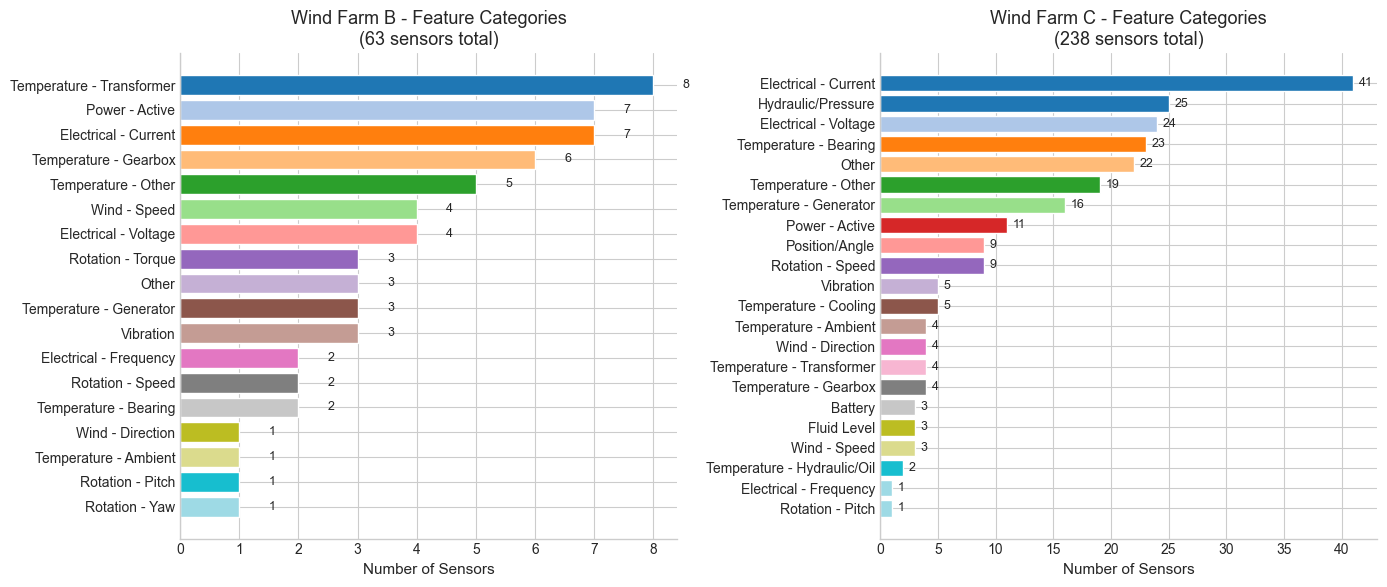

In [16]:
# Visualizar categorias de features
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (farm, features_df) in zip(axes, [('B', features_b), ('C', features_c)]):
    category_counts = features_df['category'].value_counts()
    colors = plt.cm.tab20(np.linspace(0, 1, len(category_counts)))
    
    bars = ax.barh(range(len(category_counts)), category_counts.values, color=colors)
    ax.set_yticks(range(len(category_counts)))
    ax.set_yticklabels(category_counts.index)
    ax.set_xlabel('Number of Sensors')
    ax.set_title(f'Wind Farm {farm} - Feature Categories\n({len(features_df)} sensors total)')
    ax.invert_yaxis()
    
    # Añadir etiquetas de valor
    for bar, val in zip(bars, category_counts.values):
        ax.text(val + 0.5, bar.get_y() + bar.get_height()/2, str(val), 
                va='center', fontsize=9)

plt.tight_layout()
save_figure(fig, 'feature_categories')
plt.show()

### 3.2 Canales clave para el mantenimiento predictivo

A partir de la revisión bibliográfica (Turnbull, Carroll y McDonald, 2021; Jankauskas et al., 2023; Barnabei et al., 2025) se identifican los canales más relevantes para detectar fallos de multiplicadora y de generador.

In [17]:
KEY_FEATURE_PATTERNS = {
    'Gearbox Temperature': ['gearbox', 'gear'],
    'Generator Temperature': ['generator'],
    'Bearing Temperature': ['bearing'],
    'Rotor Temperature': ['rotor'],
    'Ambient Temperature': ['ambient', 'outside'],
    'Oil Temperature': ['oil temp', 'oil tank temp'],
    'Active Power': ['active power'],
    'Wind Speed': ['wind speed'],
    'Rotor Speed': ['rotor speed'],
    'Gearbox Speed': ['gearbox rotational', 'gearbox speed']
}

def find_key_features(features_df: pd.DataFrame, patterns: Dict) -> pd.DataFrame:
    results = []
    for key_name, search_terms in patterns.items():
        for _, row in features_df.iterrows():
            desc_lower = row['description'].lower()
            if any(term in desc_lower for term in search_terms):
                results.append({
                    'key_category': key_name,
                    'sensor_name': row['sensor_name'],
                    'description': row['description'],
                    'unit': row['unit'],
                    'statistics_type': row['statistics_type']
                })
    return pd.DataFrame(results)

key_features_b = find_key_features(features_b, KEY_FEATURE_PATTERNS)
key_features_c = find_key_features(features_c, KEY_FEATURE_PATTERNS)

print("Key Features for Predictive Maintenance:")
print(f"\nFarm B: {len(key_features_b)} sensors identified")
print(key_features_b.groupby('key_category').size())

print(f"\nFarm C: {len(key_features_c)} sensors identified")
print(key_features_c.groupby('key_category').size())

print("\nKey Features - Farm B (detailed):")
key_features_b.sort_values('key_category')

Key Features for Predictive Maintenance:

Farm B: 36 sensors identified
key_category
Active Power             6
Ambient Temperature      1
Bearing Temperature      8
Gearbox Speed            1
Gearbox Temperature      7
Generator Temperature    4
Oil Temperature          1
Rotor Speed              1
Rotor Temperature        3
Wind Speed               4
dtype: int64

Farm C: 107 sensors identified
key_category
Active Power             11
Ambient Temperature       4
Bearing Temperature      24
Gearbox Temperature      17
Generator Temperature    22
Oil Temperature           7
Rotor Speed               4
Rotor Temperature        15
Wind Speed                3
dtype: int64

Key Features - Farm B (detailed):


,key_category,sensor_name,description,unit,statistics_type
29,Active Power,power_62,Active power,kW,"minimum,std_dev,maximum,average"
28,Active Power,reactive_power_11,Reactive power,kvar,"average,std_dev,maximum,minimum"
27,Active Power,sensor_3,Total positive active power,kWh,"maximum,std_dev,minimum,average"
26,Active Power,sensor_2,Total positive reactive power,kvarh,"average,minimum,maximum,std_dev"
25,Active Power,sensor_1,Total negative active power,kWh,"maximum,std_dev,average,minimum"
24,Active Power,sensor_0,Total negative reactive power,kvarh,"maximum,minimum,average,std_dev"
22,Ambient Temperature,sensor_8,Outside temperature,�C,"maximum,average,minimum,std_dev"
17,Bearing Temperature,sensor_51,Rotor bearing temperature 1,�C,"average,std_dev,maximum,minimum"
18,Bearing Temperature,sensor_52,Rotor bearing temperature 2,�C,"maximum,minimum,std_dev,average"
16,Bearing Temperature,sensor_37,Gearbox bearing temperature 4,�C,"minimum,maximum,std_dev,average"


### 3.3 Comparación de canales entre parques

Cruza las descripciones textuales de los sensores de B y de C para separar lo común de lo exclusivo.

**Solo seis canales coinciden entre parques**, entre ellos la temperatura exterior, la velocidad de viento y dos temperaturas de rodamiento del rotor; los 57 restantes de B y los 232 de C son exclusivos de cada instalación. Los dos parques no admiten un tratamiento común, ni siquiera a nivel de señal.

In [18]:
# Encontrar features comunes por similitud de descripcion
desc_b = set(features_b['description'].str.lower().str.strip())
desc_c = set(features_c['description'].str.lower().str.strip())

common_descriptions = desc_b.intersection(desc_c)
only_b = desc_b - desc_c
only_c = desc_c - desc_b

print(f"Feature Comparison (by description):")
print(f"  Common features: {len(common_descriptions)}")
print(f"  Only in Farm B: {len(only_b)}")
print(f"  Only in Farm C: {len(only_c)}")

print(f"\nCommon features:")
for desc in sorted(common_descriptions)[:20]:
    print(f"  - {desc}")
if len(common_descriptions) > 20:
    print(f"  ... and {len(common_descriptions) - 20} more")

Feature Comparison (by description):
  Common features: 6
  Only in Farm B: 57
  Only in Farm C: 232

Common features:
  - hub temperature
  - outside temperature
  - rotor bearing temperature 1
  - rotor bearing temperature 2
  - wind speed 1
  - wind speed 2


In [19]:
# Crear diccionario de features combinando ambas granjas
feature_dict = pd.concat([
    features_b[['sensor_name', 'description', 'unit', 'category', 'farm']],
    features_c[['sensor_name', 'description', 'unit', 'category', 'farm']]
])

save_table(feature_dict, 'feature_dictionary')
print(f"Feature dictionary saved: {len(feature_dict)} entries")

Saved: .\results\tables\feature_dictionary.csv
Feature dictionary saved: 301 entries


## 4. Análisis del estado operativo

Cada fila lleva un estado operativo, y su distribución vuelve a diferenciar a los dos parques. Sirve para tres cosas: seleccionar los datos de entrenamiento, identificar los periodos de parada y entender los patrones de mantenimiento.

> A tener en cuenta:
>
> La literatura suele entrenar sobre operación normal y espera (los estados 0 y 2), pero **el estado de espera no aparece en ninguno de los dos parques**. En este trabajo el comportamiento normal se aprende únicamente sobre filas de operación normal, y el resto de estados se filtra.
>
> La operación normal ronda el 89 % en ambos parques (89.84 % en B, 89.22 % en C), pero **el resto se reparte de forma asimétrica**. B registra un 5.51 % de operación degradada y ningún punto de servicio, mientras que C registra un 7.74 % de servicio y ninguno de operación degradada. Sugiere políticas de registro distintas entre operadores.

In [20]:
# Agregar distribucion de estados del resumen
status_cols = [f'status_{i}_count' for i in range(6)]

status_by_farm = dataset_summary.groupby('farm')[status_cols].sum()
status_by_farm.columns = [STATUS_TYPES[i] for i in range(6)]

# Calcular porcentajes
status_pct = status_by_farm.div(status_by_farm.sum(axis=1), axis=0) * 100

print("Status Distribution by Farm (count):")
print(status_by_farm)
print("\nStatus Distribution by Farm (percentage):")
print(status_pct.round(2))

Status Distribution by Farm (count):
      Normal Operation  Derated Operation  Idling  Service  Downtime  Other
farm                                                                       
B               771801              47359       0        0      3636  36269
C              2843548                  0       0   246764     20036  76788

Status Distribution by Farm (percentage):
      Normal Operation  Derated Operation  Idling  Service  Downtime  Other
farm                                                                       
B              89.8400             5.5100  0.0000   0.0000    0.4200 4.2200
C              89.2200             0.0000  0.0000   7.7400    0.6300 2.4100


Saved: .\results\figures\status_distribution.png


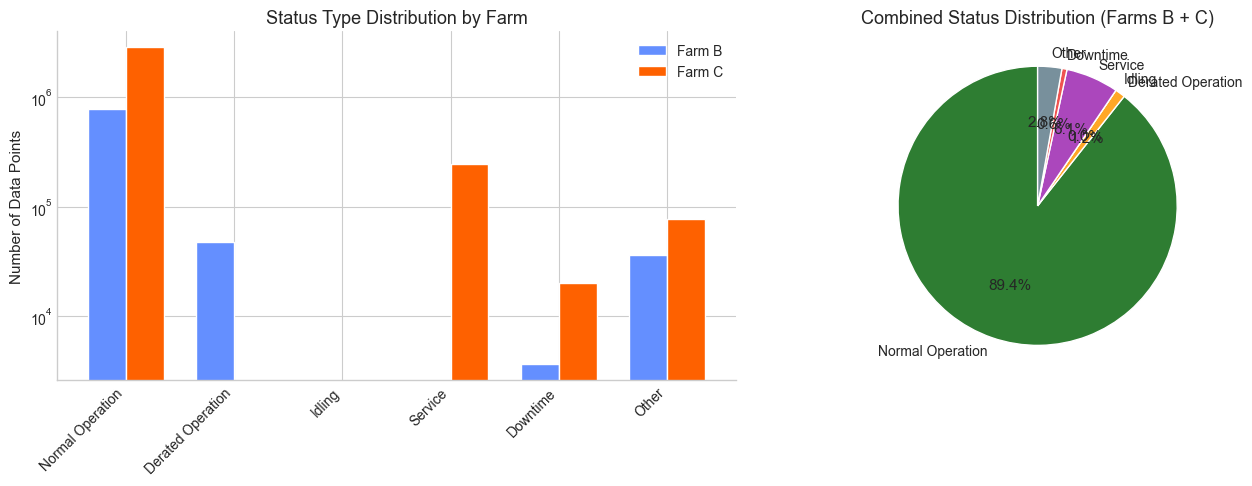

In [21]:
# Visualizar distribucion de estados
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico de barras de conteos
status_by_farm_t = status_by_farm.T
x = np.arange(len(status_by_farm_t))
width = 0.35

ax = axes[0]
bars1 = ax.bar(x - width/2, status_by_farm_t['B'], width, label='Farm B', color=FARM_COLORS['B'])
bars2 = ax.bar(x + width/2, status_by_farm_t['C'], width, label='Farm C', color=FARM_COLORS['C'])

ax.set_ylabel('Number of Data Points')
ax.set_title('Status Type Distribution by Farm')
ax.set_xticks(x)
ax.set_xticklabels(status_by_farm_t.index, rotation=45, ha='right')
ax.legend()
ax.set_yscale('log')

# Graficos de tarta para porcentajes
ax = axes[1]

# Porcentaje combinado
total_status = status_by_farm.sum()
colors = [STATUS_COLORS[i] for i in range(6)]

wedges, texts, autotexts = ax.pie(total_status.values, 
                                   labels=total_status.index,
                                   autopct='%1.1f%%',
                                   colors=colors,
                                   startangle=90)
ax.set_title('Combined Status Distribution (Farms B + C)')

plt.tight_layout()
save_figure(fig, 'status_distribution')
plt.show()

### 4.1 Definición de los estados operativos

Significado de cada uno de los seis estados que define el *benchmark* CARE.

In [22]:
# Crear documentacion de tipos de estado
status_doc = pd.DataFrame([
    {'status_id': 0, 'name': 'Normal Operation', 
     'description': 'The turbine is in normal power production mode',
     'use_for_training': 'Yes'},
    {'status_id': 1, 'name': 'Derated Operation', 
     'description': 'Derated power generation with a power restriction',
     'use_for_training': 'No'},
    {'status_id': 2, 'name': 'Idling', 
     'description': 'Asset is idling and waits to operate again',
     'use_for_training': 'Yes'},
    {'status_id': 3, 'name': 'Service', 
     'description': 'Asset is in service mode / service team is at the site',
     'use_for_training': 'No'},
    {'status_id': 4, 'name': 'Downtime', 
     'description': 'Asset is down due to a fault or other reasons',
     'use_for_training': 'No'},
    {'status_id': 5, 'name': 'Other', 
     'description': 'Other operational states',
     'use_for_training': 'No'}
])

status_doc

,status_id,name,description,use_for_training
0,0,Normal Operation,The turbine is in normal power production mode,Yes
1,1,Derated Operation,Derated power generation with a power restriction,No
2,2,Idling,Asset is idling and waits to operate again,Yes
3,3,Service,Asset is in service mode / service team is at ...,No
4,4,Downtime,Asset is down due to a fault or other reasons,No
5,5,Other,Other operational states,No


## 5. Análisis temporal

Resolución de muestreo, patrones de huecos y completitud del registro.

La morfología de los huecos motiva dos decisiones del ventaneo, que las ventanas se construyan solo dentro de segmentos temporalmente continuos, y que se exija un mínimo del 90 % de valores válidos por ventana.

### 5.1 Verificación de la resolución temporal

Comprueba que el registro sigue la frecuencia de muestreo nominal de 10 minutos y mide la completitud de cada *sub-dataset*.

In [23]:
def analyze_time_resolution(farm: str, event_id: int) -> Dict:
    df = load_dataset(farm, event_id)
    df = df.sort_values('time_stamp')
    
    # Calcular diferencias temporales
    time_diff = df['time_stamp'].diff().dropna()
    time_diff_minutes = time_diff.dt.total_seconds() / 60
    
    return {
        'farm': farm,
        'event_id': event_id,
        'n_records': len(df),
        'min_interval_min': time_diff_minutes.min(),
        'max_interval_min': time_diff_minutes.max(),
        'mean_interval_min': time_diff_minutes.mean(),
        'median_interval_min': time_diff_minutes.median(),
        'std_interval_min': time_diff_minutes.std(),
        'n_gaps': (time_diff_minutes > 10.5).sum(),
        'expected_records': int((df['time_stamp'].max() - df['time_stamp'].min()).total_seconds() / 600) + 1,
        'completeness_pct': len(df) / (int((df['time_stamp'].max() - df['time_stamp'].min()).total_seconds() / 600) + 1) * 100
    }

# Analizar resolucion temporal de todos los datasets
time_analysis = []
for farm in ['B', 'C']:
    event_ids = get_dataset_files(farm)
    for event_id in tqdm(event_ids, desc=f"Analyzing time resolution - Farm {farm}"):
        try:
            result = analyze_time_resolution(farm, event_id)
            time_analysis.append(result)
        except Exception as e:
            print(f"Error with Farm {farm}, Event {event_id}: {e}")

time_analysis_df = pd.DataFrame(time_analysis)

Analyzing time resolution - Farm B:   0%|          | 0/15 [00:00<?, ?it/s]

Analyzing time resolution - Farm C:   0%|          | 0/58 [00:00<?, ?it/s]

In [24]:
# Resumen del analisis de resolucion temporal
print("Time Resolution Summary:")

for farm in ['B', 'C']:
    farm_data = time_analysis_df[time_analysis_df['farm'] == farm]
    print(f"\nFarm {farm}:")
    print(f"  Expected interval: {DATA_FREQUENCY_MINUTES} minutes")
    print(f"  Median interval: {farm_data['median_interval_min'].median():.2f} minutes")
    print(f"  Mean completeness: {farm_data['completeness_pct'].mean():.2f}%")
    print(f"  Datasets with gaps: {(farm_data['n_gaps'] > 0).sum()} / {len(farm_data)}")
    print(f"  Max gap observed: {farm_data['max_interval_min'].max():.1f} minutes")

Time Resolution Summary:

Farm B:
  Expected interval: 10 minutes
  Median interval: 10.00 minutes
  Mean completeness: 99.84%
  Datasets with gaps: 15 / 15
  Max gap observed: 3110.0 minutes

Farm C:
  Expected interval: 10 minutes
  Median interval: 10.00 minutes
  Mean completeness: 99.37%
  Datasets with gaps: 23 / 58
  Max gap observed: 14410.0 minutes


Saved: .\results\figures\temporal_completeness.png


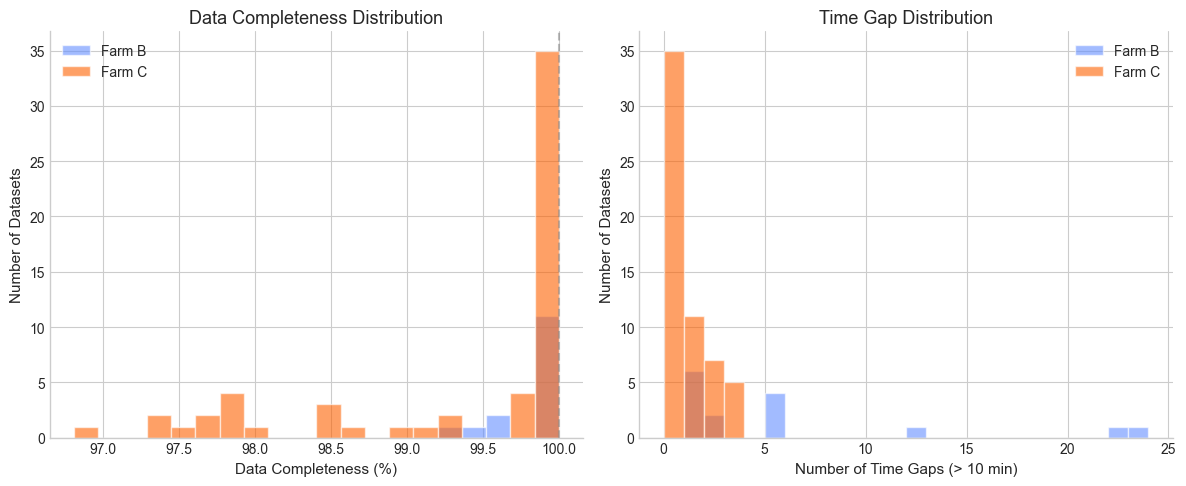

In [25]:
# Visualizar completitud de datos
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Calcular bins comunes para el histograma de completitud
all_completeness = time_analysis_df["completeness_pct"]
completeness_bins = np.linspace(all_completeness.min(), all_completeness.max(), 21)

# Histograma de completitud
ax = axes[0]
for farm in ["B", "C"]:
    farm_data = time_analysis_df[time_analysis_df["farm"] == farm]
    ax.hist(farm_data["completeness_pct"], bins=completeness_bins, alpha=0.6, 
            label=f"Farm {farm}", color=FARM_COLORS[farm])
ax.set_xlabel("Data Completeness (%)")
ax.set_ylabel("Number of Datasets")
ax.set_title("Data Completeness Distribution")
ax.legend()
ax.axvline(x=100, color="gray", linestyle="--", alpha=0.5)

# Numero de huecos (bins comunes)
ax = axes[1]
all_gaps = time_analysis_df["n_gaps"]
gap_bins = range(0, int(all_gaps.max()) + 2)
for farm in ["B", "C"]:
    farm_data = time_analysis_df[time_analysis_df["farm"] == farm]
    ax.hist(farm_data["n_gaps"], bins=gap_bins, 
            alpha=0.6, label=f"Farm {farm}", color=FARM_COLORS[farm])
ax.set_xlabel("Number of Time Gaps (> 10 min)")
ax.set_ylabel("Number of Datasets")
ax.set_title("Time Gap Distribution")
ax.legend()

plt.tight_layout()
save_figure(fig, "temporal_completeness")
plt.show()

## 6. Resumen estadístico

Estadísticas descriptivas de los canales clave: distribuciones, valores atípicos y calidad del registro.

**Ninguna variable supera el 10 % de valores ausentes en ninguno de los dos parques**, lo que evita eliminaciones masivas. El filtro intercuartílico preliminar, en cambio, marca valores atípicos en 198 variables de B y 880 de C, limpiar esos valores sin destruir la señal útil es el cometido del preprocesado.

In [26]:
def compute_feature_statistics(farm: str, sample_size: int = 5) -> pd.DataFrame:
    event_ids = get_dataset_files(farm)[:sample_size]
    
    all_stats = []
    
    for event_id in tqdm(event_ids, desc=f"Computing stats - Farm {farm}"):
        df = load_dataset(farm, event_id)
        
        # Obtener columnas numericas (excluyendo metadatos)
        numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        exclude_cols = ['asset_id', 'id', 'status_type_id', 'event_id']
        feature_cols = [c for c in numeric_cols if c not in exclude_cols]
        
        for col in feature_cols:
            data = df[col].dropna()
            if len(data) > 0:
                q1, q3 = data.quantile([0.25, 0.75])
                iqr = q3 - q1
                
                stats = {
                    'farm': farm,
                    'event_id': event_id,
                    'feature': col,
                    'count': len(data),
                    'missing': df[col].isna().sum(),
                    'missing_pct': df[col].isna().mean() * 100,
                    'mean': data.mean(),
                    'std': data.std(),
                    'min': data.min(),
                    'q25': q1,
                    'median': data.median(),
                    'q75': q3,
                    'max': data.max(),
                    'n_zeros': (data == 0).sum(),
                    'n_outliers_iqr': ((data < q1 - 1.5*iqr) | (data > q3 + 1.5*iqr)).sum()
                }
                all_stats.append(stats)
    
    return pd.DataFrame(all_stats)

# Calcular estadisticas (usando muestra para ahorrar tiempo)
stats_b = compute_feature_statistics('B', sample_size=5)
stats_c = compute_feature_statistics('C', sample_size=5)

print(f"Statistics computed for {len(stats_b)} feature-dataset combinations (Farm B)")
print(f"Statistics computed for {len(stats_c)} feature-dataset combinations (Farm C)")

Computing stats - Farm B:   0%|          | 0/5 [00:00<?, ?it/s]

Computing stats - Farm C:   0%|          | 0/5 [00:00<?, ?it/s]

Statistics computed for 1260 feature-dataset combinations (Farm B)
Statistics computed for 4760 feature-dataset combinations (Farm C)


In [27]:
# Agregar estadisticas por feature
def aggregate_feature_stats(stats_df: pd.DataFrame) -> pd.DataFrame:
    agg = stats_df.groupby('feature').agg({
        'mean': 'mean',
        'std': 'mean',
        'min': 'min',
        'max': 'max',
        'missing_pct': 'mean',
        'n_outliers_iqr': 'sum'
    }).round(4)
    
    agg.columns = ['mean_avg', 'std_avg', 'global_min', 'global_max', 'missing_pct_avg', 'total_outliers']
    return agg.sort_values('missing_pct_avg', ascending=False)

agg_stats_b = aggregate_feature_stats(stats_b)
agg_stats_c = aggregate_feature_stats(stats_c)

print("Farm B - Features with highest missing data:")
agg_stats_b.head(10)

Farm B - Features with highest missing data:


,mean_avg,std_avg,global_min,global_max,missing_pct_avg,total_outliers
feature,,,,,,
power_62_std,0.2702,0.2810,-0.0785,1.0257,0.0065,0
power_62_max,0.4219,0.3580,-0.0066,1.1285,0.0014,0
power_58_avg,0.4827,0.4069,0.0000,1.0290,0.0000,0
power_58_max,0.5557,0.4090,0.0000,1.0290,0.0000,0
power_58_std,0.4122,0.3987,0.0000,1.0290,0.0000,0
power_58_min,0.0363,0.0451,0.0000,0.4729,0.0000,9406
power_62_avg,0.3455,0.3178,-0.0094,1.0312,0.0000,0
power_62_min,0.0342,0.0413,0.0000,0.5164,0.0000,22790
reactive_power_11_avg,0.0154,0.0304,-0.3855,0.2626,0.0000,11886


In [28]:
# Identificar features con problemas de calidad de datos
print("\nData Quality Summary:")

for farm, agg_stats in [('B', agg_stats_b), ('C', agg_stats_c)]:
    high_missing = (agg_stats['missing_pct_avg'] > 10).sum()
    has_outliers = (agg_stats['total_outliers'] > 0).sum()
    
    print(f"\nFarm {farm}:")
    print(f"  Features with >10% missing: {high_missing}")
    print(f"  Features with outliers (IQR): {has_outliers}")


Data Quality Summary:

Farm B:
  Features with >10% missing: 0
  Features with outliers (IQR): 198

Farm C:
  Features with >10% missing: 0
  Features with outliers (IQR): 880


## 7. Análisis de correlaciones

Correlaciones entre los canales clave, para identificar relaciones y estimar el margen de reducción de dimensionalidad.

In [29]:
def compute_correlation_matrix(farm: str, event_id: int,
                               feature_patterns: List[str] = None) -> pd.DataFrame:
    df = load_dataset(farm, event_id)

    # Seleccionar features que coincidan con patrones
    if feature_patterns:
        cols = []
        for pattern in feature_patterns:
            cols.extend([c for c in df.columns if pattern.lower() in c.lower()])
        cols = list(set(cols))
    else:
        numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        exclude = ['asset_id', 'id', 'status_type_id', 'event_id']
        cols = [c for c in numeric_cols if c not in exclude]

    # Limitar a features con sufijo _avg para correlacion mas limpia
    cols = [c for c in cols if '_avg' in c][:30]

    if len(cols) < 2:
        return pd.DataFrame()

    return df[cols].corr()

# Calcular correlacion para un dataset de muestra de la Granja B
sample_event = dataset_summary[
    (dataset_summary['farm'] == 'B') &
    (dataset_summary['event_label'] == 'anomaly')
]['event_id'].iloc[0]

corr_matrix_b = compute_correlation_matrix('B', sample_event)
print(f"Correlation matrix computed for Farm B, Event {sample_event}")
print(f"Shape: {corr_matrix_b.shape}")

Correlation matrix computed for Farm B, Event 7
Shape: (30, 30)


Saved: .\results\figures\correlation_matrix_farm_b.png


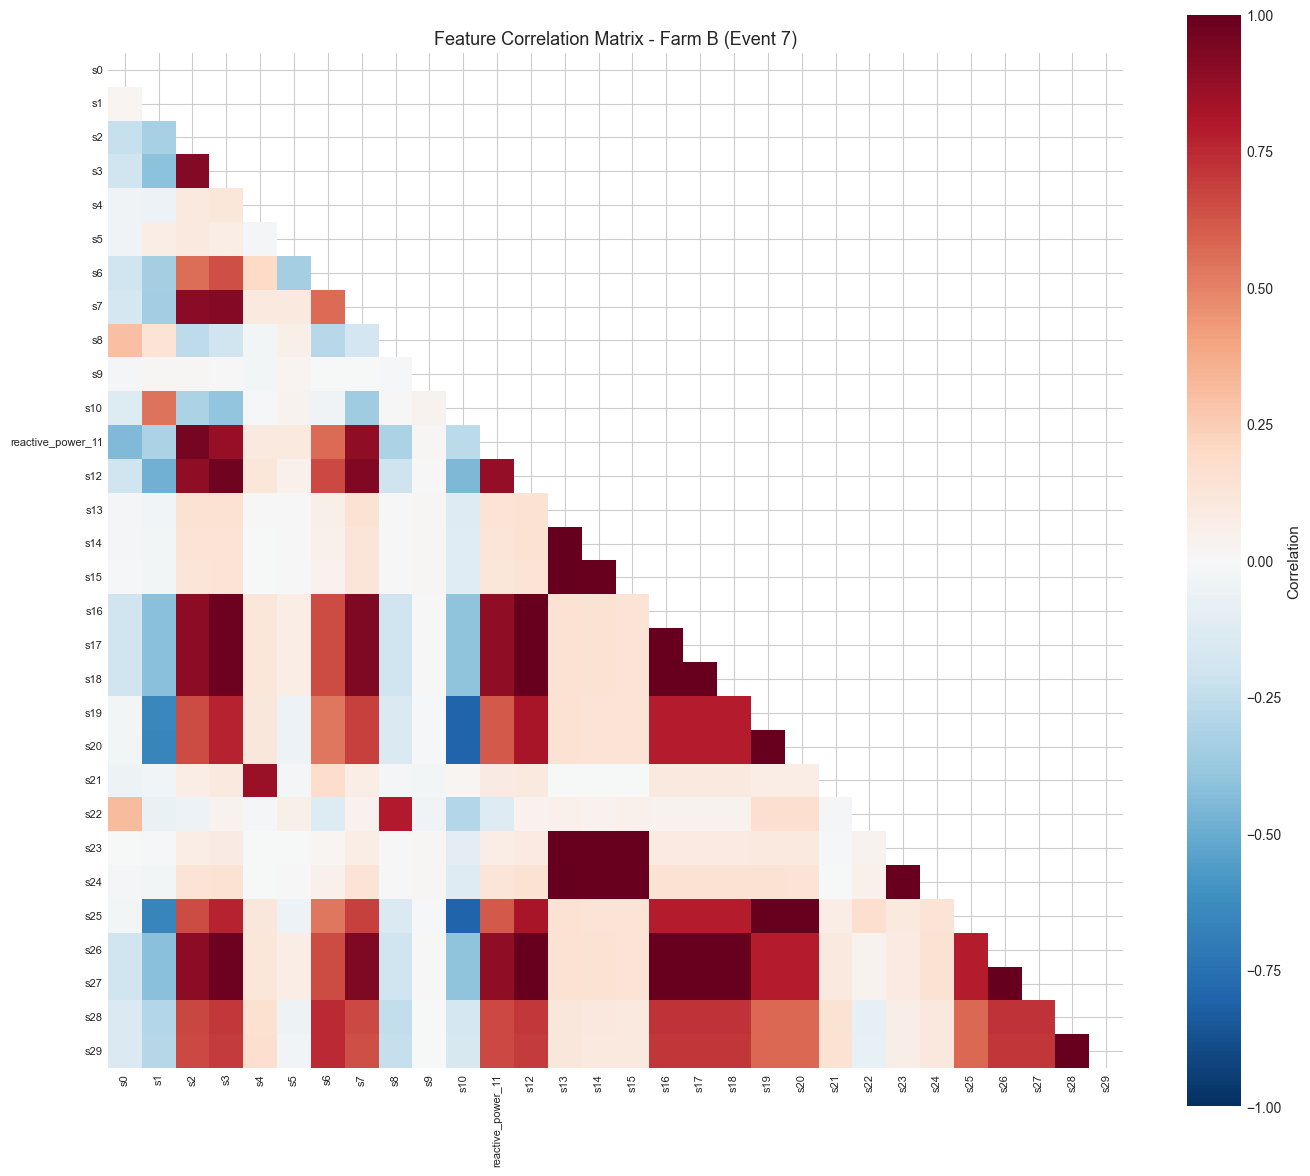

In [30]:
# Visualizar matriz de correlacion
if len(corr_matrix_b) > 0:
    fig, ax = plt.subplots(figsize=(14, 12))

    # Limpiar nombres de columnas para visualizacion
    clean_names = [c.replace('_avg', '').replace('sensor_', 's') for c in corr_matrix_b.columns]

    mask = np.triu(np.ones_like(corr_matrix_b, dtype=bool))

    sns.heatmap(corr_matrix_b, mask=mask, annot=False, cmap='RdBu_r',
                center=0, vmin=-1, vmax=1, square=True,
                xticklabels=clean_names, yticklabels=clean_names,
                cbar_kws={'label': 'Correlation'})

    plt.title(f'Feature Correlation Matrix - Farm B (Event {sample_event})')
    plt.xticks(rotation=90, fontsize=8)
    plt.yticks(fontsize=8)

    plt.tight_layout()
    save_figure(fig, 'correlation_matrix_farm_b')
    plt.show()

In [31]:
# Encontrar pares de features altamente correladas
def find_high_correlations(corr_matrix: pd.DataFrame, threshold: float = 0.9) -> pd.DataFrame:
    pairs = []
    for i, col1 in enumerate(corr_matrix.columns):
        for j, col2 in enumerate(corr_matrix.columns[i+1:], i+1):
            corr = corr_matrix.iloc[i, j]
            if abs(corr) >= threshold:
                pairs.append({
                    'feature_1': col1,
                    'feature_2': col2,
                    'correlation': corr
                })
    return pd.DataFrame(pairs).sort_values('correlation', key=abs, ascending=False)

high_corr_pairs = find_high_correlations(corr_matrix_b, threshold=0.9)
print(f"Feature pairs with |correlation| >= 0.9: {len(high_corr_pairs)}")
if len(high_corr_pairs) > 0:
    print("\nTop 10 highly correlated pairs:")
    display(high_corr_pairs.head(10))

# Guardar matriz de correlación
save_table(corr_matrix_b, 'correlation_matrix')

Feature pairs with |correlation| >= 0.9: 45

Top 10 highly correlated pairs:


,feature_1,feature_2,correlation
36,sensor_17_avg,sensor_27_avg,1.0000
34,sensor_17_avg,sensor_18_avg,1.0000
38,sensor_18_avg,sensor_27_avg,1.0000
33,sensor_16_avg,sensor_27_avg,1.0000
30,sensor_16_avg,sensor_17_avg,1.0000
37,sensor_18_avg,sensor_26_avg,1.0000
31,sensor_16_avg,sensor_18_avg,1.0000
35,sensor_17_avg,sensor_26_avg,1.0000
43,sensor_26_avg,sensor_27_avg,1.0000
32,sensor_16_avg,sensor_26_avg,1.0000


Saved: .\results\tables\correlation_matrix.csv


### 7.1 La curva de potencia

Relación entre velocidad de viento y potencia generada. Es la comprobación de que el dato es físicamente coherente.

> **Conviene fijarse en el eje de ordenadas.** La potencia está normalizada y escalada a un rango aproximado de 0 a 1, como el resto de magnitudes del *benchmark*, de modo que cualquier filtro basado en umbrales absolutos de kilovatios carece de sentido.

Saved: .\results\figures\power_curve_farm_b.png


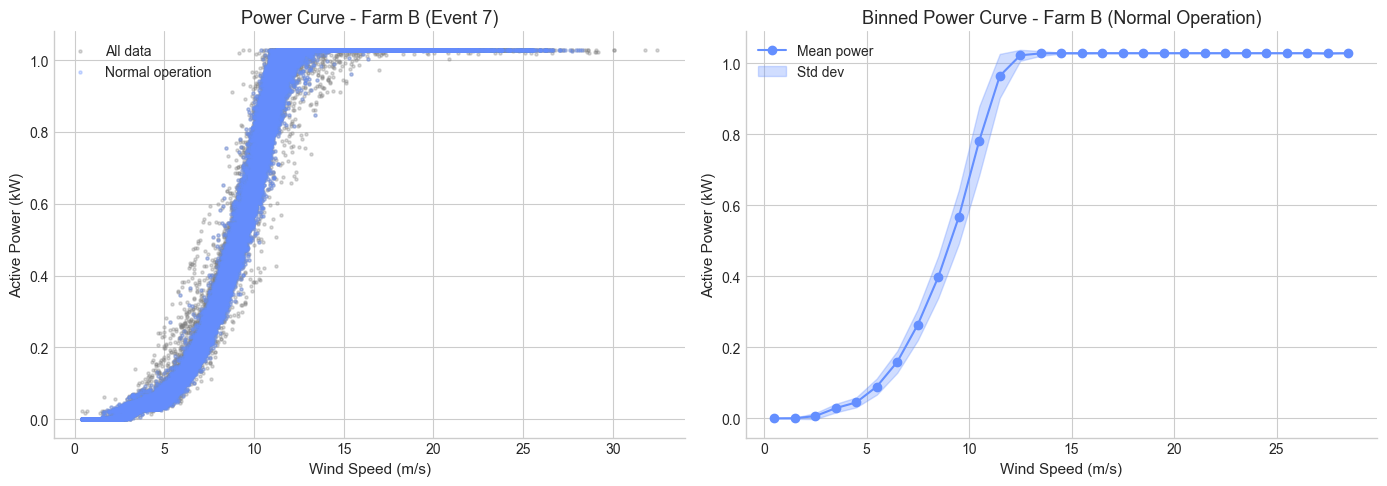

In [32]:
def plot_power_curve(farm: str, event_id: int):
    df = load_dataset(farm, event_id)
    
    # Encontrar columnas de velocidad de viento y potencia
    wind_col = [c for c in df.columns if 'wind_speed' in c.lower() and '_avg' in c]
    power_col = [c for c in df.columns if 'power' in c.lower() and '_avg' in c and 'reactive' not in c.lower()]
    
    if not wind_col or not power_col:
        print(f"Could not find wind speed or power columns for Farm {farm}")
        return None
    
    wind_col = wind_col[0]
    power_col = power_col[0]
    
    # Filtrar solo operacion normal
    mask = df['status_type_id'].isin(NORMAL_STATUS_IDS)
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Scatter plot - todos los datos
    ax = axes[0]
    ax.scatter(df[wind_col], df[power_col], alpha=0.3, s=5, c=COLORS['gray'], label='All data')
    ax.scatter(df.loc[mask, wind_col], df.loc[mask, power_col], alpha=0.3, s=5, c=FARM_COLORS[farm], label='Normal operation')
    ax.set_xlabel('Wind Speed (m/s)')
    ax.set_ylabel('Active Power (kW)')
    ax.set_title(f'Power Curve - Farm {farm} (Event {event_id})')
    ax.legend()
    
    # Media por intervalos
    ax = axes[1]
    normal_data = df[mask][[wind_col, power_col]].dropna()
    if len(normal_data) > 0:
        normal_data['wind_bin'] = pd.cut(normal_data[wind_col], bins=np.arange(0, 30, 1))
        binned = normal_data.groupby('wind_bin')[power_col].agg(['mean', 'std']).dropna()
        binned.index = [interval.mid for interval in binned.index]
        
        ax.plot(binned.index, binned['mean'], 'o-', color=FARM_COLORS[farm], label='Mean power')
        ax.fill_between(binned.index, 
                        binned['mean'] - binned['std'], 
                        binned['mean'] + binned['std'], 
                        alpha=0.3, color=FARM_COLORS[farm], label='Std dev')
    
    ax.set_xlabel('Wind Speed (m/s)')
    ax.set_ylabel('Active Power (kW)')
    ax.set_title(f'Binned Power Curve - Farm {farm} (Normal Operation)')
    ax.legend()
    
    plt.tight_layout()
    return fig


# Representar curvas de potencia
fig = plot_power_curve('B', sample_event)
if fig:
    save_figure(fig, 'power_curve_farm_b')
    plt.show()

## 8. Los eventos de anomalía

Tipos de fallo, duraciones y patrones temporales de los 33 eventos anómalos de los dos parques.

Los 6 eventos de B son largos y homogéneos, mientras que los 27 de C son más cortos y variados.

In [33]:
# Filtrar solo eventos de anomalia
anomalies = event_info[event_info['event_label'] == 'anomaly'].copy()

print(f"Total anomaly events: {len(anomalies)}")
print(f"  Farm B: {len(anomalies[anomalies['farm'] == 'B'])}")
print(f"  Farm C: {len(anomalies[anomalies['farm'] == 'C'])}")

# Mostrar resumen de anomalias
anomalies[['event_id', 'farm', 'event_start', 'event_end', 'duration_days', 'event_description']].sort_values(['farm', 'event_id'])

Total anomaly events: 33
  Farm B: 6
  Farm C: 27


,event_id,farm,event_start,event_end,duration_days,event_description
1,7,B,2023-07-01 00:00:00,2023-08-01 00:00:00,31.0000,high temperature in transformer cell
4,19,B,2023-02-03 00:00:00,2023-02-23 00:00:00,20.0000,high temperature in transformer cell
3,27,B,2023-09-01 00:00:00,2023-11-01 00:00:00,61.0000,Turbine is stopped due to a main bearing damage
0,34,B,2023-08-24 00:00:00,2023-09-15 00:00:00,22.0000,high temperature in transformer cell
2,53,B,2023-12-26 16:40:00,2024-02-06 16:30:00,41.9931,Rotor Bearing 2 - Damage
5,77,B,2023-06-01 00:00:00,2023-07-31 00:00:00,60.0000,Turbine is in standstill since 01.08 due to ro...
19,4,C,2023-07-31 10:00:00,2023-08-19 10:00:00,19.0000,23020 : Axis 3 not ready-to-operate
36,5,C,2023-02-02 00:00:00,2023-02-05 15:00:00,3.6250,WEC in failure - current measurement own consu...
34,9,C,2023-08-05 07:30:00,2023-08-26 09:30:00,21.0833,PENDING19_PREV_YAW_Grease pump defective
29,11,C,2023-10-17 12:30:00,2023-11-08 10:30:00,21.9167,P20_DGUV-v3 RCD 28F1 NC310 defective + 0 : P20...


In [34]:
# Categorizar anomalias por tipo de fallo
def categorize_fault(description: str) -> str:
    if pd.isna(description) or description == '':
        return 'Unknown'
    
    desc_lower = str(description).lower()
    
    if any(term in desc_lower for term in ['bearing', 'rotor bearing', 'main bearing']):
        return 'Bearing Fault'
    elif any(term in desc_lower for term in ['gearbox', 'gear']):
        return 'Gearbox Fault'
    elif any(term in desc_lower for term in ['pitch']):
        return 'Pitch System'
    elif any(term in desc_lower for term in ['temperature', 'temp', 'high temp']):
        return 'Temperature Issue'
    elif any(term in desc_lower for term in ['hydraulic', 'oil']):
        return 'Hydraulic System'
    elif any(term in desc_lower for term in ['converter', 'electrical', 'voltage']):
        return 'Electrical/Converter'
    elif any(term in desc_lower for term in ['communication', 'bk1120', 'beckhoff']):
        return 'Communication Fault'
    elif any(term in desc_lower for term in ['transformer']):
        return 'Transformer'
    elif any(term in desc_lower for term in ['yaw', 'carbon brush']):
        return 'Yaw System'
    elif any(term in desc_lower for term in ['brake', 'rotor brake']):
        return 'Brake System'
    elif any(term in desc_lower for term in ['battery']):
        return 'Battery'
    else:
        return 'Other'

anomalies['fault_category'] = anomalies['event_description'].apply(categorize_fault)

print("Fault Categories Distribution:")
fault_dist = anomalies.groupby(['farm', 'fault_category']).size().unstack(fill_value=0)
print(fault_dist)

Fault Categories Distribution:
fault_category  Battery  Bearing Fault  Brake System  Communication Fault  \
farm                                                                        
B                     0              3             0                    0   
C                     1              0             1                    2   

fault_category  Electrical/Converter  Gearbox Fault  Hydraulic System  Other  \
farm                                                                           
B                                  0              0                 0      0   
C                                  2              3                 1      9   

fault_category  Pitch System  Temperature Issue  Transformer  Yaw System  
farm                                                                      
B                          0                  3            0           0  
C                          5                  1            1           1  


Saved: .\results\figures\anomaly_distribution.png


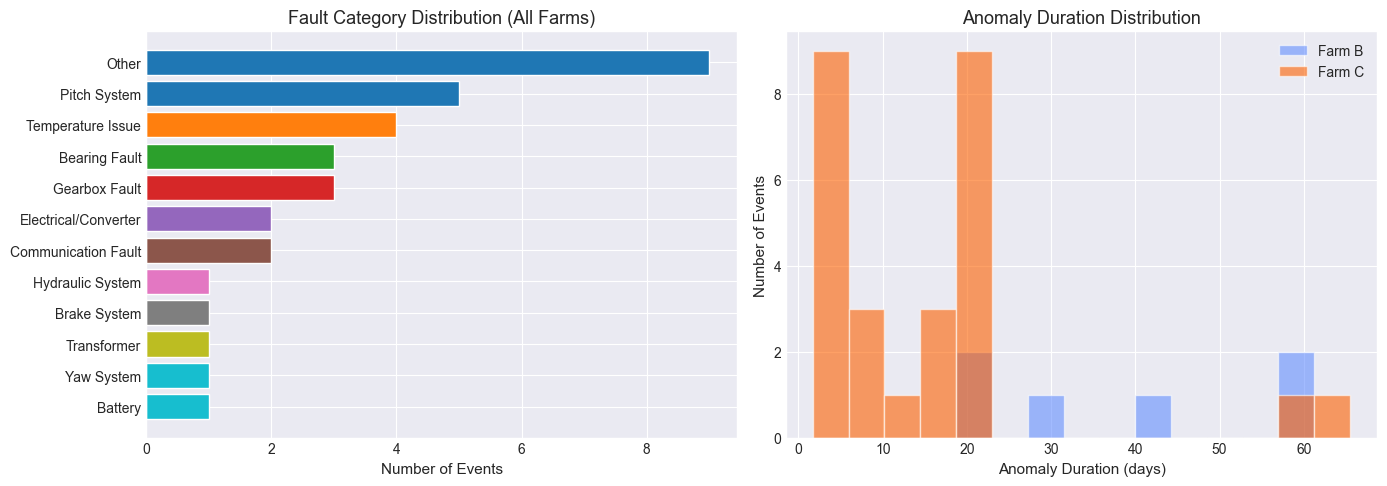

Anomaly Duration Statistics (days):
       count    mean     std     min     25%     50%     75%     max
farm                                                                
B     6.0000 39.3322 18.1510 20.0000 24.2500 36.4965 55.4983 61.0000
C    27.0000 15.6559 15.4105  1.7014  4.5451 14.9931 20.2292 65.5139


In [35]:
# Visualizar distribuciin de fallos
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Por granja
ax = axes[0]
fault_counts = anomalies["fault_category"].value_counts()
colors = plt.cm.tab10(np.linspace(0, 1, len(fault_counts)))
ax.barh(range(len(fault_counts)), fault_counts.values, color=colors)
ax.set_yticks(range(len(fault_counts)))
ax.set_yticklabels(fault_counts.index)
ax.set_xlabel("Number of Events")
ax.set_title("Fault Category Distribution (All Farms)")
ax.invert_yaxis()

# Distribucion de duraciones (bins comunes)
ax = axes[1]
all_durations = anomalies["duration_days"]
duration_bins = np.linspace(all_durations.min(), all_durations.max(), 16)
for farm in ["B", "C"]:
    farm_data = anomalies[anomalies["farm"] == farm]
    ax.hist(farm_data["duration_days"], bins=duration_bins, alpha=0.6, 
            label=f"Farm {farm}", color=FARM_COLORS[farm])
ax.set_xlabel("Anomaly Duration (days)")
ax.set_ylabel("Number of Events")
ax.set_title("Anomaly Duration Distribution")
ax.legend()

plt.tight_layout()
save_figure(fig, "anomaly_distribution")
plt.show()

# Estadisticas de duracion
print("Anomaly Duration Statistics (days):")
print(anomalies.groupby("farm")["duration_days"].describe())

In [36]:
# Guardar resumen de anomalias
anomaly_summary = anomalies[['event_id', 'farm', 'event_label', 'event_start', 'event_end', 
                            'duration_days', 'fault_category', 'event_description']].copy()
save_table(anomaly_summary, 'anomaly_summary')
print(f"Anomaly summary saved: {len(anomaly_summary)} events")

Saved: .\results\tables\anomaly_summary.csv
Anomaly summary saved: 33 events


## 9. Comportamiento normal frente a anómalo

Series temporales de dos casos de anomalía del parque B, para ver de cerca los patrones que preceden al fallo.

Visualizing Bearing Fault Case: Farm B, Event 53
Saved: .\results\figures\anomaly_case_bearing_B_53.png


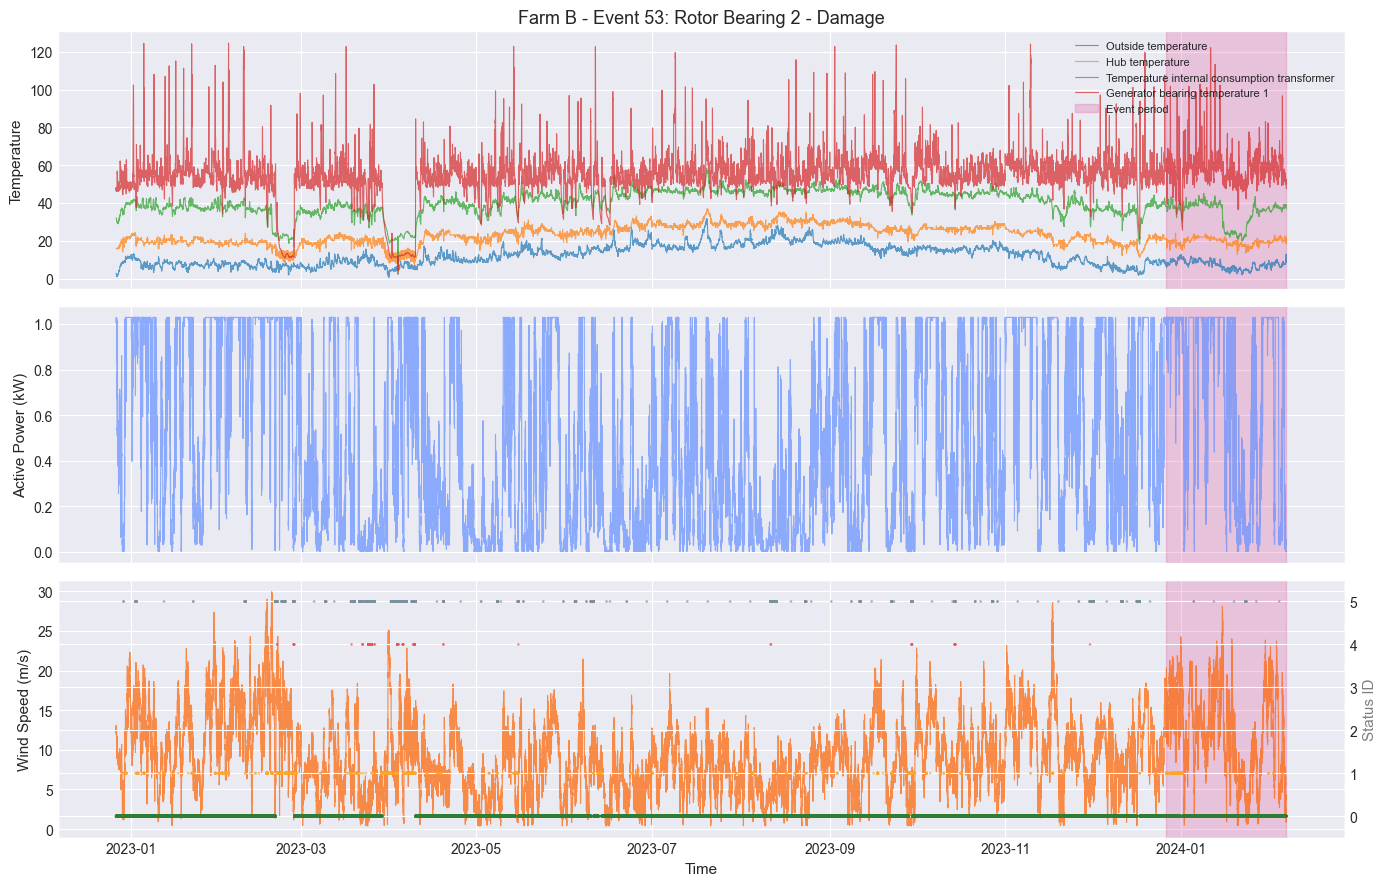

In [37]:
def plot_anomaly_case(farm: str, event_id: int):
    df = load_dataset(farm, event_id)
    event_row = event_info[(event_info["farm"] == farm) & (event_info["event_id"] == event_id)].iloc[0]
    
    # Obtener informacion del evento
    event_start = event_row["event_start"]
    event_end = event_row["event_end"]
    label = event_row["event_label"]
    description = event_row["event_description"]
    fault_cat = event_row.get("fault_category", "Other")
    
    # Mapear categorias de fallo a palabras clave para seleccion de temperatura
    fault_temp_keywords = {
        "Bearing Fault": ["bearing", "main bearing", "rotor"],
        "Gearbox Fault": ["gearbox", "gear"],
        "Temperature Issue": ["gearbox", "generator", "bearing", "oil"],
        "Hydraulic System": ["hydraulic", "oil"],
        "Electrical/Converter": ["generator", "stator", "converter"],
        "Transformer": ["transformer"],
    }
    
    # Encontrar columnas de temperatura usando las descripciones (nombres genericos sensor_XX)
    features_df = features_b if farm == "B" else features_c
    priority_keywords = fault_temp_keywords.get(fault_cat, [])
    
    # Identificar sensores de temperatura por sus descripciones
    temp_sensors = features_df[features_df["description"].str.contains("temp", case=False, na=False)]
    avg_cols_in_df = [c for c in df.columns if c.endswith("_avg")]
    all_temp_cols = [c for c in avg_cols_in_df if c.replace("_avg", "") in temp_sensors["sensor_name"].values]
    
    # Incluir tambien columnas cuyo nombre contiene 'temp' (p.ej. hub_temperature_avg)
    name_based = [c for c in avg_cols_in_df if "temp" in c.lower() and c not in all_temp_cols]
    all_temp_cols = all_temp_cols + name_based
    
    # Seleccionar temperaturas relevantes segun el tipo de fallo
    priority_cols = []
    other_temp_cols = []
    for col in all_temp_cols:
        sensor_name = col.replace("_avg", "")
        desc_row = features_df[features_df["sensor_name"] == sensor_name]
        if len(desc_row) > 0:
            desc = desc_row["description"].values[0].lower()
            if any(kw in desc for kw in priority_keywords):
                priority_cols.append(col)
            else:
                other_temp_cols.append(col)
        else:
            other_temp_cols.append(col)
    
    # Tomar hasta 4 columnas prioritarias, completar con otras si es necesario
    temp_cols = (priority_cols + other_temp_cols)[:4]
    
    wind_col = [c for c in df.columns if "wind_speed" in c.lower() and "_avg" in c]
    power_col = [c for c in df.columns if "power" in c.lower() and "_avg" in c and "reactive" not in c.lower()]
    
    wind_col = wind_col[0] if wind_col else None
    power_col = power_col[0] if power_col else None
    
    n_plots = 3
    fig, axes = plt.subplots(n_plots, 1, figsize=(14, 3*n_plots), sharex=True)
    
    # Grafico 1: Features de temperatura
    ax = axes[0]
    for i, col in enumerate(temp_cols):
        # Usar descripcion como etiqueta si esta disponible
        sensor_name = col.replace("_avg", "")
        desc_row = features_df[features_df["sensor_name"] == sensor_name]
        lbl = desc_row["description"].values[0] if len(desc_row) > 0 else col.replace("_avg", "").replace("sensor_", "s")
        ax.plot(df["time_stamp"], df[col], alpha=0.7, label=lbl, linewidth=0.8)
    ax.axvspan(event_start, event_end, alpha=0.2, color=LABEL_COLORS[label], label="Event period")
    ax.set_ylabel("Temperature")
    ax.set_title(f"Farm {farm} - Event {event_id}: {description}")
    ax.legend(loc="upper right", fontsize=8)
    
    # Grafico 2: Potencia generada
    ax = axes[1]
    if power_col:
        ax.plot(df["time_stamp"], df[power_col], alpha=0.7, color=COLORS["blue"], linewidth=0.8)
        ax.axvspan(event_start, event_end, alpha=0.2, color=LABEL_COLORS[label])
    ax.set_ylabel("Active Power (kW)")
    
    # Grafico 3: Velocidad del viento y estado
    ax = axes[2]
    if wind_col:
        ax.plot(df["time_stamp"], df[wind_col], alpha=0.7, color=COLORS["orange"], linewidth=0.8, label="Wind speed")
    ax.axvspan(event_start, event_end, alpha=0.2, color=LABEL_COLORS[label])
    ax.set_ylabel("Wind Speed (m/s)")
    ax.set_xlabel("Time")
    
    # Añadir marcadores de estado
    ax2 = ax.twinx()
    ax2.scatter(df["time_stamp"], df["status_type_id"], c=df["status_type_id"].map(STATUS_COLORS), 
                s=1, alpha=0.5)
    ax2.set_ylabel("Status ID", color="gray")
    ax2.set_ylim(-0.5, 5.5)
    
    plt.tight_layout()
    return fig

# Seleccionar casos de anomalia representativos
# Un fallo de rodamiento y un problema de temperatura
bearing_events = anomalies[anomalies["fault_category"] == "Bearing Fault"]
temp_events = anomalies[anomalies["fault_category"] == "Temperature Issue"]

if len(bearing_events) > 0:
    case = bearing_events.iloc[0]
    print(f"Visualizing Bearing Fault Case: Farm {case["farm"]}, Event {case["event_id"]}")
    fig = plot_anomaly_case(case["farm"], case["event_id"])
    save_figure(fig, f"anomaly_case_bearing_{case["farm"]}_{case["event_id"]}")
    plt.show()

Visualizing Temperature Issue Case: Farm B, Event 34
Saved: .\results\figures\anomaly_case_temp_B_34.png


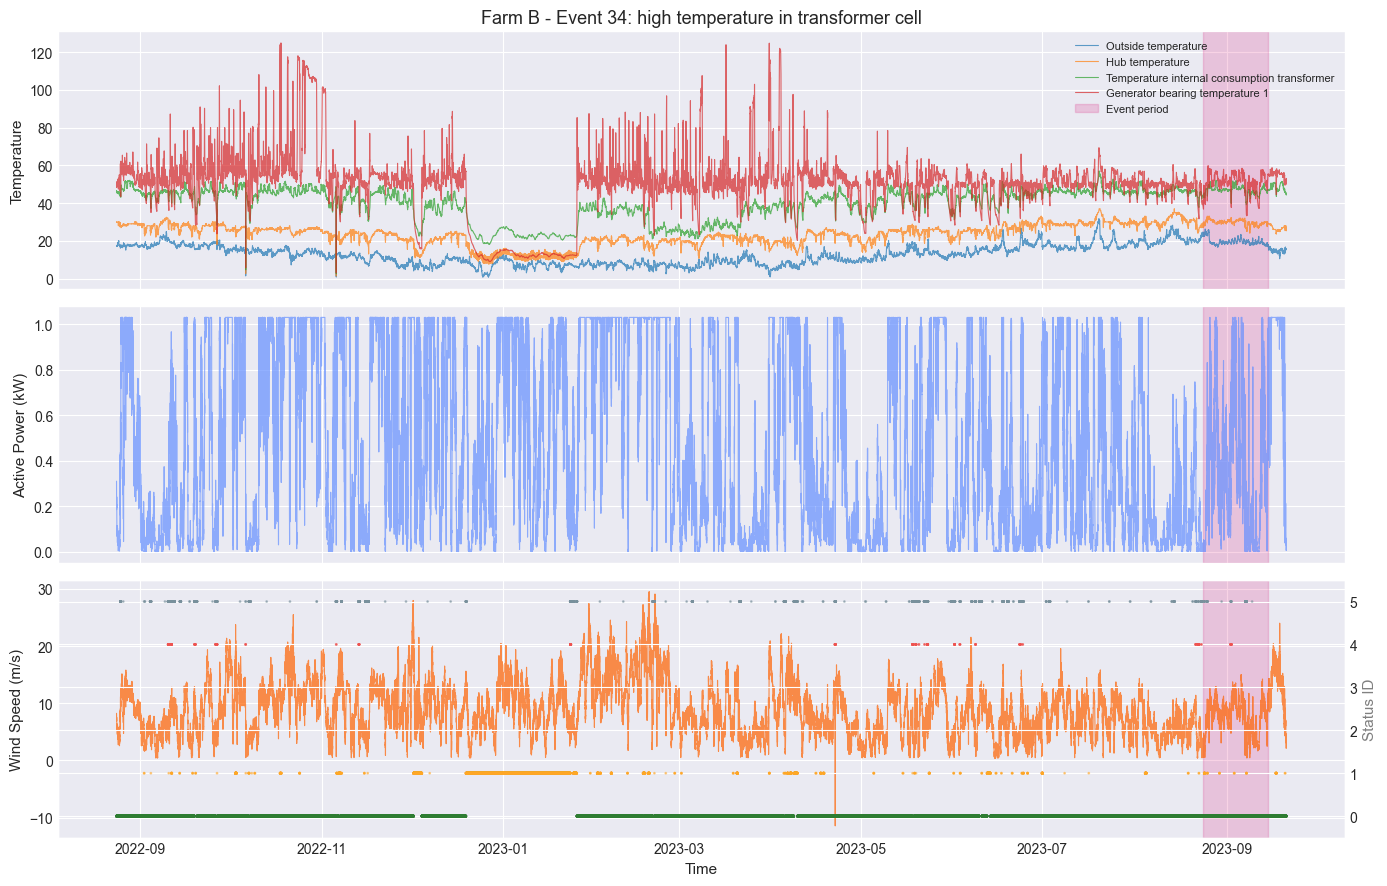

In [38]:

# Visualizar un caso de anomalia de temperatura
if len(temp_events) > 0:
    case = temp_events.iloc[0]
    print(f"Visualizing Temperature Issue Case: Farm {case['farm']}, Event {case['event_id']}")
    fig = plot_anomaly_case(case['farm'], case['event_id'])
    save_figure(fig, f"anomaly_case_temp_{case['farm']}_{case['event_id']}")
    plt.show()

## CONCLUSIONES

| | **Parque B** | **Parque C** |
|---|---|---|
| Filas (puntos diezminutales) | 859 065 | 3 187 136 |
| Turbinas | 9 | 22 |
| *Sub-datasets* (anomalía / normal) | 15 (6 / 9) | 58 (27 / 31) |
| Canales físicos × estadísticos | 63 × 4 | 238 × 4 |
| Variables (sin metadatos) | 252 | 952 |
| Rango temporal | ene. 2022 a feb. 2024 | ene. 2022 a ene. 2024 |
| Completitud temporal media | 99.84 % | 99.37 % |
| *Sub-datasets* con huecos (el mayor) | 15 de 15 (52 h) | 23 de 58 (10 días) |
| Operación normal | 89.84 % | 89.22 % |
| Variables con valores atípicos (IQR) | 198 | 880 |
| Duración media del evento de anomalía | 39.3 días | 15.7 días |

*(La celda 18 imprime 254 y 954 variables: su recuento parte de una base distinta a la de la celda 14, que es la que recoge esta tabla y la que sigue la memoria.)*

**La conclusión a la que se llega es que los dos parques no admiten el mismo tratamiento.** Los parques comparten formato y protocolo y no se parecen en casi nada más. Solo seis canales coinciden; el reparto de estados apunta a operadores con políticas de registro distintas; los huecos son frecuentes y cortos en B, raros pero ocasionalmente largos en C; y los eventos de B duran más del doble y se reducen a dos familias, frente al abanico de casos de C.

### Tres decisiones del preprocesado que salen de aquí

El siguiente notebook, `00_preprocessing.ipynb`, las ejecuta:

- **Filtro de estado.** El comportamiento normal se aprende únicamente sobre filas de operación normal; el resto se filtra. No se usa el estado de espera porque no existe en estos datos.
- **Ventaneo.** Ventanas solo dentro de segmentos temporalmente continuos, con un mínimo del 90 % de valores válidos, por la morfología de los huecos.
- **Curva de potencia.** El filtro usa un umbral relativo (el 2 % del percentil 99 de la potencia observada) y no un valor físico absoluto, porque la potencia viene normalizada.